# Customer segmentation with clustering

Understanding and serving customers are two of the retail industry's most important strategic marketing objectives. This project explores customer purchasing patterns and develops segments to inform potential marketing activity.

## Objectives
- Review data quality and aggregate order lines to one row per customer.
- Create five features: Frequency, Observed_Revenue, Avg_Unit_Cost, Age and Recency.
- Compare clustering diagnostics and interpret a practical three-segment K-means solution.
- Visualise the segments and identify hypotheses for further validation.

## Dataset attribution
The supplied reference attributes CUSTOMERS_CLEAN to SAS (2024), last revised 15 December 2021. The dataset is accessed through the existing [FourthRev teaching repository](https://github.com/FourthRevGitHub/CAM_DS_Public-Data-Sets/blob/main/Course%201/Week%206/CUSTOMERS_CLEAN.zip). This is a historical e-commerce dataset; the business scenario is illustrative. Source dimensions and dates are calculated below rather than assumed. The reference does not establish redistribution permissions; raw data is not included in this project.

**Execution and provenance:** this portfolio refresh selectively executes preparation, full-data k=3 K-means, the segment summary, box plots and final PCA in a fresh kernel. Saved full-data k=1–10 WCSS, k=2–5 silhouettes and diagnostic plots are retained from the earlier completed diagnostic cells. Supplementary dendrograms and the unseeded t-SNE figure are outputs from the original analysis and were not regenerated. This is not a complete Run All execution. All executed analysis uses every customer.

# Data Import

In [1]:
# import necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from joblib import Memory
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm
from scipy.cluster.hierarchy import (
    dendrogram,
    linkage,
)
from sklearn.manifold import TSNE
from sklearn.base import clone
from IPython.display import display
RANDOM_STATE = 42

# Expensive calculations require explicit opt-in; no sampling.
RECOMPUTE_DIAGNOSTICS = False
RUN_HIERARCHICAL = False
RUN_TSNE = False


In [2]:
# Load the data
data = pd.read_csv(
    "https://github.com/FourthRevGitHub/CAM_DS_Public-Data-Sets/raw/main/Course%201/Week%206/CUSTOMERS_CLEAN.zip"
)

source_rows, source_columns = data.shape
print(f"Source: {source_rows:,} order lines, {source_columns} columns")

Source: 951,669 order lines, 20 columns


# Data Inspection

First we'll review the data and perform any data cleanse or pre-processing.

## Data Quality Checks

We will perform basic data quality checks, view the dataframe metadata to determine assigned datatypes, and determine the size of the dataset.

Data quality checks:

- Duplicated rows
- Missing data checks
- Trailing / Leading whitespace

In [3]:
# View the metadata with the info function.
print("Datatypes: \n" + str(data.info()) + "\n")

# Check for null values
print(
    "\nData quality check (1) detect null values in columns:\n"
    + str(data.isna().sum())
    + "\n"
)

# Check for duplicated rows
duplicated_rows = data.duplicated().sum()
print(
    "\nData quality check (2) count of duplicated rows: "
    + str(duplicated_rows)
)


<class 'pandas.DataFrame'>
RangeIndex: 951669 entries, 0 to 951668
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Quantity              951669 non-null  int64
 1   City                  951534 non-null  str  
 2   Continent             951669 non-null  str  
 3   Postal_Code           947953 non-null  str  
 4   State_Province        834477 non-null  str  
 5   Order_Date            951669 non-null  str  
 6   Delivery_Date         951669 non-null  str  
 7   Total Revenue         951669 non-null  str  
 8   Unit Cost             951669 non-null  str  
 9   Discount              951669 non-null  str  
 10  OrderTypeLabel        951669 non-null  str  
 11  CustomerCountryLabel  951669 non-null  str  
 12  Customer_BirthDate    951669 non-null  str  
 13  Customer_Group        951669 non-null  str  
 14  Customer_Type         951669 non-null  str  
 15  Order ID              951669 non-null  int64



Data quality check (2) count of duplicated rows: 21


**Initial data quality checks**

The outputs above show the actual row count, datatypes, missing values and duplicate count. Financial and date fields need parsing before aggregation. Address fields are not used in this analysis and are dropped; their missing values still limit wider use of the dataset.

We will remove exact duplicate rows, convert financial and date fields, check conversion failures and retain only fields required for the five customer features. Exact row duplicates are treated as duplicate observations; the source does not independently confirm this assumption.

In [4]:
print(f"Rows involved in exact duplicate groups: {data.duplicated(keep=False).sum():,}")

Rows involved in exact duplicate groups: 42


### Remove Duplicates

Retain one occurrence of each exact row under the duplicate-observation assumption.

In [5]:
# drop duplicates
data.drop_duplicates(inplace=True)


# now drop columns that we will not use, and not validate further
data.drop(
    columns=[
        "City",
        "Continent",
        "Postal_Code",
        "State_Province",
        "Discount",
        "OrderTypeLabel",
        "CustomerCountryLabel",
        "Customer_Group",
        "Customer_Type",
        "Profit",
        "Days to Delivery",
        "Loyalty Num",
        "Quantity",
    ],
    inplace=True,
)

print(f"Working data: {len(data):,} rows, {data.shape[1]} columns")

Working data: 951,648 rows, 7 columns


### Convert Financial Data and Validate

Split Total Revenue and Unit Cost into currency markers and numeric values. Check markers, conversion failures and non-positive values before aggregation. Observed_Revenue will be summed customer revenue during the dataset period, not predicted lifetime value. Avg_Unit_Cost will be the unweighted mean of order-line unit costs, not a quantity-weighted cost or selling price.

In [6]:
# 1st interrogate and convert 'Unit Cost' and 'Total Revenue' columns


def split_currency(series):
    """function to split currency and value from a string
    uses regex to extract currency and numeric value
    currency can be 3 letter code or symbol(s)
    (non-digit, non-dot, non-minus characters)
    value is numeric part, allowing for commas, dots, and minus sign
    """

    # detect accounting-style negatives
    is_paren = series.str.contains(r"\(", regex=True)

    # return dataframe with 1 column with numeric part, then replace commas, then convert to numeric
    # if conversion fails, set to NaN
    value = pd.to_numeric(
        series.str.extract(r"([-\d,\.]+)")[0].str.replace(
            ",", "", regex=False
        ),
        errors="coerce",
    )

    # apply negative sign where parentheses were present
    value = value.where(~is_paren, -value)

    # return dataframe with 1 column with currency part
    # extract the iso 3 letter code or symbol(s)
    currency = series.str.extract(r"([A-Z]{3}|[^\d\.-]+)")[0]

    return currency, value


data["Unit_Cost_Currency"], data["Unit_Cost"] = split_currency(
    data["Unit Cost"]
)
data["Total_Revenue_Currency"], data["Total_Revenue"] = split_currency(
    data["Total Revenue"]
)


print(f"Working data: {len(data):,} rows, {data.shape[1]} columns")

Working data: 951,648 rows, 11 columns


In [7]:
# complete the data quality checks for these columns

# determine number of currency values
print(
    f"Unique Unit_Cost_Currency values: {data['Unit_Cost_Currency'].unique()}"
)
print(
    f"Unique Total_Revenue_Currency values: "
    f"{data['Total_Revenue_Currency'].unique()}"
)

# check for values that could not be converted
print(
    f"Count of Unit_Cost values that could not be converted: "
    f"{data['Unit_Cost'].isna().sum()}"
)
print(
    f"Count of Total_Revenue that could not be converted: "
    f"{data['Total_Revenue'].isna().sum()}"
)


# count the zero or -ve values
print(f"Count of Unit_Cost values <= 0: {(data['Unit_Cost'] <= 0).sum()}")

print(
    f"Count of Total_Revenue values <= 0: {(data['Total_Revenue'] <= 0).sum()}"
)

Unique Unit_Cost_Currency values: <ArrowStringArray>
['$']
Length: 1, dtype: str
Unique Total_Revenue_Currency values: <ArrowStringArray>
['$']
Length: 1, dtype: str
Count of Unit_Cost values that could not be converted: 0
Count of Total_Revenue that could not be converted: 0
Count of Unit_Cost values <= 0: 0
Count of Total_Revenue values <= 0: 0


The checks above report currency markers, conversion failures and non-positive values. A shared dollar marker is not sufficient on its own to identify currency; the source description treats revenue as USD. We assume financial amounts are comparable and perform no currency conversion.

### Convert Date String Values to Datetime

The date values held in string (format DDmmmYYYY) will be converted to true datetime fields, any conversion errors will be investigated.

In [8]:
# drop the original columns and currency columns (we will not use them further)
data.drop(
    columns=[
        "Unit Cost",
        "Total Revenue",
        "Unit_Cost_Currency",
        "Total_Revenue_Currency",
    ],
    inplace=True,
)


def DDmmmYYYY_str_to_date(series):
    # function to convert date strings in DDmmmYYYY format to datetime
    return pd.to_datetime(series, format="%d%b%Y", errors="coerce")


data.rename(
    columns={
        "Order_Date": "Order_Date_Str",
        "Delivery_Date": "Delivery_Date_Str",
        "Customer_BirthDate": "Customer_BirthDate_Str",
    },
    inplace=True,
)


data["Order_Date"] = DDmmmYYYY_str_to_date(data["Order_Date_Str"])
data["Delivery_Date"] = DDmmmYYYY_str_to_date(data["Delivery_Date_Str"])
data["Customer_BirthDate"] = DDmmmYYYY_str_to_date(
    data["Customer_BirthDate_Str"]
)

print(
    f"Count of Order_Date values that could not be converted:"
    f" {data['Order_Date'].isna().sum()}"
)
print(
    f"Count of Delivery_Date values that could not be converted:"
    f" {data['Delivery_Date'].isna().sum()}"
)
print(
    f"Count of Customer_BirthDate values that could not be converted:"
    f" {data['Customer_BirthDate'].isna().sum()}"
)


print(f"Working data: {len(data):,} rows, {data.shape[1]} columns")

Count of Order_Date values that could not be converted: 0
Count of Delivery_Date values that could not be converted: 0
Count of Customer_BirthDate values that could not be converted: 0
Working data: 951,648 rows, 10 columns


Date conversion failures are reported above. The following checks stop execution if required model inputs are invalid.

In [9]:
# drop the original string date columns
data.drop(
    columns=[
        "Order_Date_Str",
        "Delivery_Date_Str",
        "Customer_BirthDate_Str",
    ],
    inplace=True,
)

print(f"Working data: {len(data):,} rows, {data.shape[1]} columns")
assert data[['Order_Date', 'Delivery_Date', 'Customer_BirthDate', 'Total_Revenue', 'Unit_Cost', 'Customer ID']].notna().all().all()
assert (data[['Total_Revenue', 'Unit_Cost']] > 0).all().all()
assert (data['Delivery_Date'] >= data['Order_Date']).all()
assert data.groupby('Customer ID')['Customer_BirthDate'].nunique().max() == 1
print(f"Order period: {data['Order_Date'].min().date()} to {data['Order_Date'].max().date()}")

Working data: 951,648 rows, 7 columns
Order period: 2012-01-01 to 2016-12-30


## Aggregate Data and Create Analysis Features

Aggregate by Customer ID:
- Frequency: distinct order count during the dataset period.
- Observed_Revenue: sum of order-line revenue during the dataset period; this is not predicted lifetime value.
- Avg_Unit_Cost: unweighted mean of order-line unit costs. Each line receives equal weight regardless of quantity.
- Age: completed years at analysis_date.
- Recency: days from the last order to analysis_date.

We retain the existing max delivery date + 7 days convention as a reproducible historical snapshot. The seven-day buffer is an analysis convention, not an estimated churn threshold. This avoids ageing the historical data against today's date. Customer ID is an identifier outside the five modelling features.

In [10]:
customer_data = (
    data.groupby("Customer ID")
    .agg(
        Frequency=("Order ID", "nunique"),
        Observed_Revenue=("Total_Revenue", "sum"),
        max_Order_Date=("Order_Date", "max"),
        Avg_Unit_Cost=("Unit_Cost", "mean"),
        Customer_BirthDate=("Customer_BirthDate", "max"),
    )
    .reset_index()
)


analysis_date = data['Delivery_Date'].max().normalize() + pd.Timedelta(days=7)

def age_at(birth_dates, reference_date):
    # Explicit parentheses prevent comparison / bitwise operator precedence errors.
    return (reference_date.year - birth_dates.dt.year - (
        (reference_date.month < birth_dates.dt.month)
        | ((reference_date.month == birth_dates.dt.month)
           & (reference_date.day < birth_dates.dt.day))
    ).astype(int))

# Verify birthdays before, on and after the analysis date, including same month.
birthday = analysis_date.replace(year=analysis_date.year - 30)
test_births = pd.Series([birthday - pd.Timedelta(days=1), birthday,
                        birthday + pd.Timedelta(days=1)])
assert age_at(test_births, analysis_date).tolist() == [30, 30, 29]
print('Birthday boundary checks passed: before=30, on=30, after=29')
customer_data['Age'] = age_at(customer_data['Customer_BirthDate'], analysis_date)
print(f'analysis_date: {analysis_date.date()} (maximum delivery date + 7 days)')

# calculate recency - days since last order
customer_data["Recency"] = (analysis_date - customer_data["max_Order_Date"]).dt.days

# drop columns no longer needed
customer_data.drop(
    columns=["max_Order_Date", "Customer_BirthDate"], inplace=True
)

selected_features = ['Frequency', 'Observed_Revenue', 'Avg_Unit_Cost', 'Age', 'Recency']
assert len(selected_features) == 5 and 'Customer ID' not in selected_features
assert customer_data[selected_features].notna().all().all()
assert (customer_data[['Age', 'Recency']] >= 0).all().all()
print(f"Customer dataset: {len(customer_data):,} customers, {len(selected_features)} modelling features plus Customer ID")

Birthday boundary checks passed: before=30, on=30, after=29
analysis_date: 2017-01-26 (maximum delivery date + 7 days)
Customer dataset: 68,300 customers, 5 modelling features plus Customer ID


# Exploratory Data Analysis

Generate descriptive statistics and visualise the data to explore patterns, distributions, and trends in the data.

## Descriptive Statistics

We will now generate descriptive statistics for all columns in the dataset, and document any insights this provides about the data.

In [11]:
customer_data[selected_features].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T

,count,mean,std,min,5%,25%,50%,75%,95%,max
Frequency,68300.0,10.950996,8.771057,1.00,1.000,5.000000,9.00,15.00000,28.000000,101.00
Observed_Revenue,68300.0,1950.148420,1719.916365,0.63,140.995,696.000000,1497.40,2709.84500,5307.163000,18860.96
Avg_Unit_Cost,68300.0,78.895675,38.005259,0.50,33.800,57.579792,73.45,92.51526,138.578175,1463.50
Age,68300.0,43.181859,17.472857,19.00,19.000,28.000000,43.00,58.00000,73.000000,74.00
Recency,68300.0,394.662167,414.511202,27.00,34.000,72.000000,217.00,566.25000,1303.000000,1851.00


## Visualise the data

We will now visualise the data with box-plots and histograms to further understand the data patterns, distributions, and trends

### Data quality & coverage

- Distributions are **not normal** for most business metrics (Frequency, Observed_Revenue, Avg Unit Cost, Recency).
- Expect skew and outliers.

---

**Frequency**
- **Median = 9, Mean ≈ 11** → right-skewed.
- 75% of customers buy **≤15 times**.
- A small group buys very frequently (max = 101).

---

**Observed_Revenue**
- **Median ≈ 1,497 vs Mean ≈ 1,950** → heavy right skew.
- Top 5% start around **5,300**, max nearly **19k**.
- Observed_Revenue is highly concentrated.

---

**Avg Unit Cost**
- Median ≈ 73, Mean ≈ 79 → skewed with extreme outliers.
- **Max = 1,463** requires investigation:
  - Rare high-ticket items, or
  - Data quality issues (mispricing, bundles, currency errors).

---

**Age**
- Centered at **43 years**, range **19–74**.
- See the refreshed descriptive statistics and plots above; skew alone does not establish normality.

---

**Recency**

  - Right skew → **Median ≈ 217, Mean ≈ 394**
  - 25%–75% range ≈ **72–566**
  - Std dev ≈ **414**
  - 50% of customers made an order within the past 217 days (relative to analysis_date)

NOTE: We calculated recency and age relevant to the **historical analysis_date**, (max delivery date + 7 days used), not today to ensure the data age does not impact distributions.

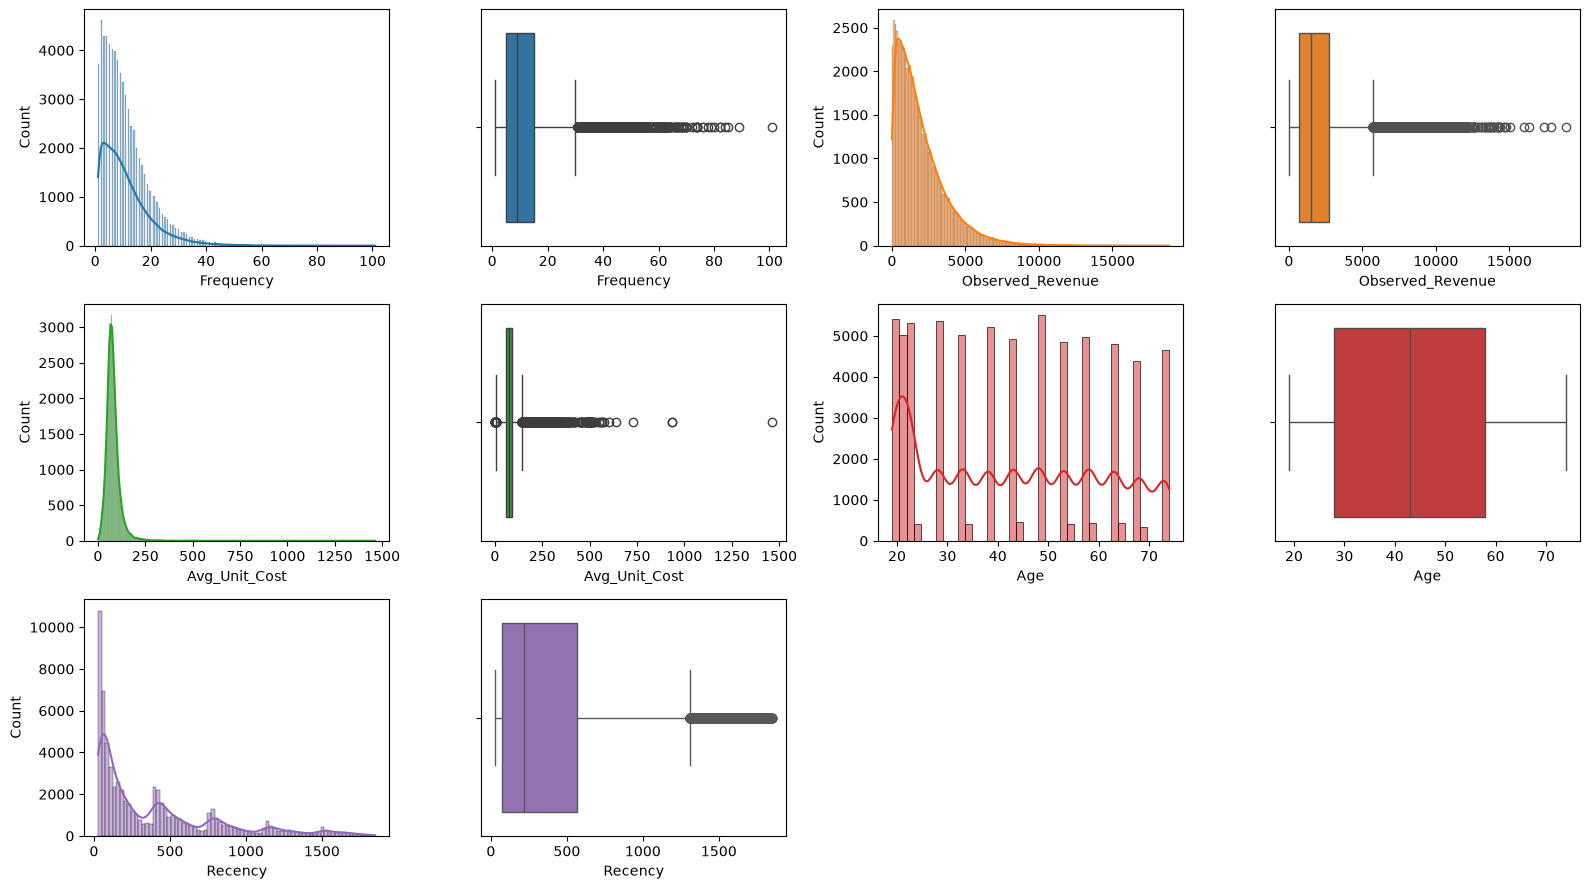

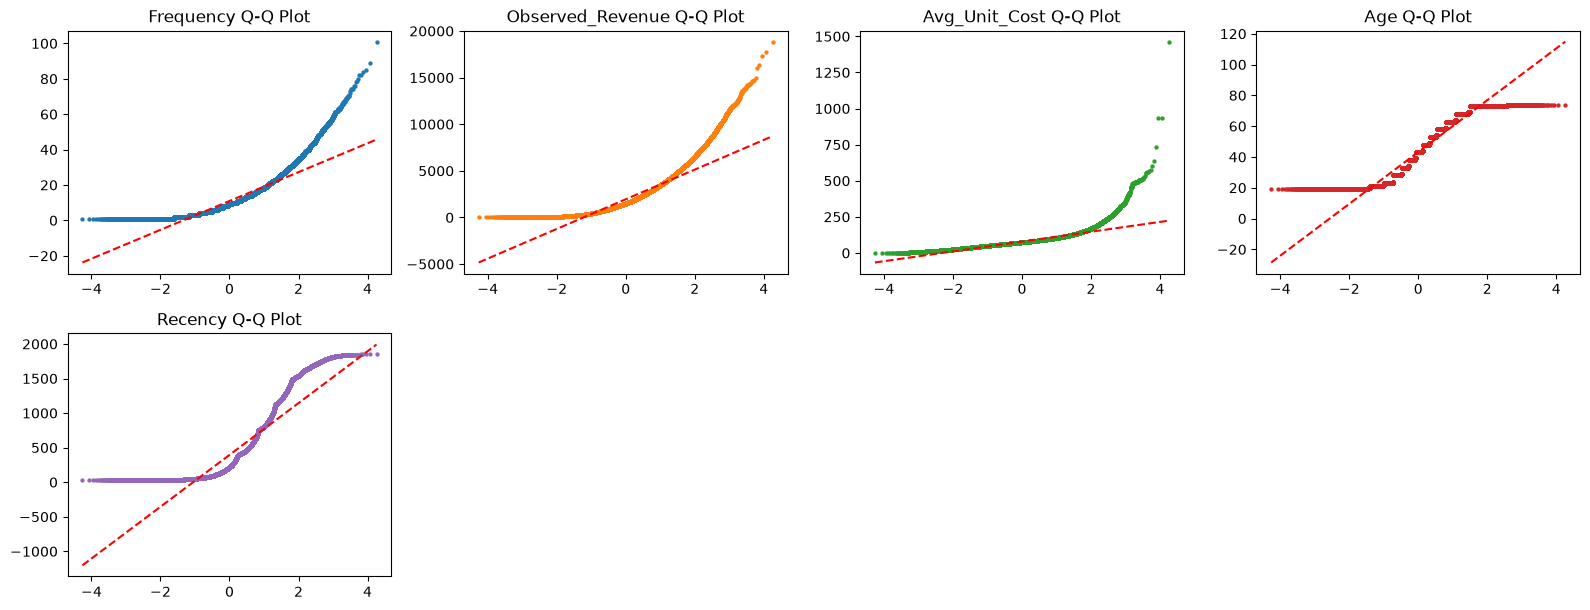

In [ ]:
# Function to add histogram subplot
def add_histogram_subplot(ax, values, color="blue", title=None):
    sns.histplot(values, kde=True, color=color, ax=ax)
    ax.set_title(title)


# Function to add boxplot subplot
def add_boxplot_subplot(ax, values, color="blue", title=None):
    sns.boxplot(x=values, color=color, ax=ax)
    ax.set_title(title)


# Function to add scatterplot subplot
def add_scatterplot_subplot(ax, x_values, y_values, color="blue", title=None):
    sns.scatterplot(
        x=x_values, y=y_values, color=color, ax=ax, edgecolor=None, s=8
    )
    ax.set_title(title)


# Function to add line to subplot
def add_line_subplot(
    ax, x_values, y_values, color="blue", title=None, linestyle="-"
):
    sns.lineplot(
        x=x_values, y=y_values, color=color, ax=ax, linestyle=linestyle
    )
    ax.set_title(title)


# choose columns to plot - exclude categorical columns
cols = selected_features

# number of plots / cols (we will be creating 2 plots per column)
n = len(cols) * 2
ncols = 4
nrows = math.ceil(n / ncols)

# create subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3))
axes = axes.ravel()  # flatten

cmap = plt.colormaps.get_cmap("tab10")  # get the colormap

# add histograms to subplots
for i, col in enumerate(cols):
    add_histogram_subplot(axes[(2 * i)], customer_data[col], cmap(i % 20))
    add_boxplot_subplot(axes[(2 * i) + 1], customer_data[col], cmap(i % 20))

# hide any unused axes
for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

n = len(cols)  # we will be creating only 1 plot per column

# Q-Q plot for normality check
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3))
axes = axes.ravel()  # flatten

for i, col in enumerate(cols):
    # use probplot to get the theoretical and ordered values - also get slope, intercept, r
    (theoretical, ordered), (slope, intercept, r) = stats.probplot(
        customer_data[col].to_numpy(), dist="norm", plot=None
    )
    ax = axes[i]

    # use scatter plot for Q-Q so that we can color the points
    add_scatterplot_subplot(ax, theoretical, ordered, cmap(i % 20))
    # Plot the theoretical line
    add_line_subplot(
        ax,
        theoretical,
        slope * theoretical + intercept,
        color="red",
        linestyle="--",
    )

    ax.set_title(col + " Q-Q Plot")

# hide any unused axes
for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## Interpretation

Customer ID is an identifier and will only be used for customer identification, outside the five modelling features. Gaps in an ID sequence do not establish incomplete data.

**Outliers are observed in the following columns:**

1) Frequency

- Bulk of customers: ~1–15 purchases
- Outliers: ~30–100+ purchases

2) Observed_Revenue

- Heavy right tail
- Extreme values up to ~18–19k

3) Avg Unit Cost

- Majority clustered ~50–100
- Severe outliers up to ~1,500

4) Recency

- Strong right tail
- Outliers at ~1,200–1,850 days

**No outliers in the following column:**

1) Age has no material outliers in the box plot, with the median near the centre of the IQR; this does not establish a normal distribution.


NOTE: Remaining columns are not normally distributed. The outliers will not be removed for further analysis as they could reflect customer behaviour, although authenticity is unverified and are important to retain for more effective customer segmentation (e.g. customers who make one off large purchases).

A summary follows:

### Outliers & Transformation Summary

| Variable | Outliers Present | Nature of Outliers |
|--------|-----------------|--------------------|
| Frequency | Yes (right tail) | Potential high-activity customers; unverified |
| Observed_Revenue | Yes (extreme right tail) | Potential high-revenue customers; unverified |
| Avg Unit Cost | Yes (extreme values) | Potential high-cost purchases or data issues; unverified |
| Age | No material outliers | |
| Recency | Yes (right tail) | Potential lower-activity customers; unverified |





StandardScaler does not remove skew. K-means and Ward linkage remain sensitive to extreme values; source or domain review is needed.

# Perform K-means clustering

We will perform k-means clustering using the following features: 'Frequency', 'Observed_Revenue', 'Avg_Unit_Cost', 'Age', 'Recency'

## Candidate values of clusters ($k$)

Before visualising the k-means clustering we must select a reasonable value for the number of clusters ($k$); to help determine this value we will use the Elbow and Silhouette score methods.

###  Column transformer and pipeline

The elbow method requires a plot of WCSS (Within-Cluster Sum of Squares) vs number of clusters - we then attempt to pick the $k$ value at the elbow / point of diminishing returns.

The saved diagnostics compare values of $k$ between 1 and 10 (inclusive) and implement via a column transformer and pipeline (for caching and reuse) as follows:

- Scale the data using StandardScaler - recommended for k-means as it is distance-based and sensitive to magnitude, and our features are on significantly different scales.
- Run KMeans, read WCSS (inertia), and store it for each value of $k$

In [12]:
# Exclude Customer ID for clustering - use as index
customer_data.set_index("Customer ID", inplace=True)

assert customer_data.index.is_unique
assert customer_data.columns.tolist() == selected_features

Selected features for clustering: ['Frequency', 'Observed_Revenue', 'Avg_Unit_Cost', 'Age', 'Recency']


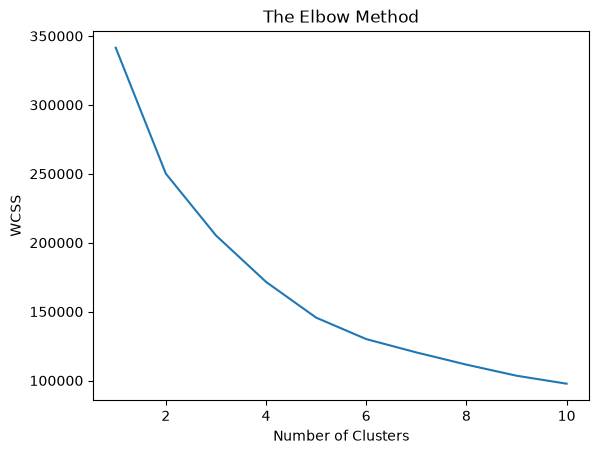

In [ ]:
if RECOMPUTE_DIAGNOSTICS:
    # Five explicit features defined during aggregation

    print(f"Selected features for clustering: {selected_features}")

    preprocessor = ColumnTransformer(
        transformers=[("num", StandardScaler(), selected_features)]
    )

    # set up caching for the pipeline
    cache = Memory(location="sk_cache", verbose=0)  # adjust location as needed

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("clusterer", KMeans(random_state=RANDOM_STATE, n_init=10)),
        ],
        memory=cache,
        verbose=False,
    )

    wcss = {}
    k_values = range(1, 11)
    pipelines = {}
    kmeans_models = {}

    for k in k_values:
        pipe_k = clone(pipeline)
        pipe_k.set_params(clusterer__n_clusters=k)
        pipe_k.fit(customer_data)
        pipelines[k] = pipe_k
        # get the kmeans models from the pipelines for later use
        kmeans_models[k] = pipe_k.named_steps["clusterer"]
        # store WCSS value for elbow method
        wcss[k] = pipe_k.named_steps["clusterer"].inertia_

    # output scaled data for later analysis
    customer_data_scaled = (
        pipelines[10].named_steps["preprocessor"].transform(customer_data)
    )

    # convert scaled data back to DataFrame and align index and columns
    customer_data_scaled = pd.DataFrame(customer_data_scaled)
    customer_data_scaled.columns = selected_features
    customer_data_scaled.index = customer_data.index

    # Now plot the elbow method chart
    plt.plot(list(k_values), [wcss[k] for k in k_values])
    plt.title("The Elbow Method")
    plt.xlabel("Number of Clusters")
    plt.ylabel("WCSS")
    plt.show()

### Elbow method interpretation

The chart of WCSS vs number of clusters shows a soft elbow. There is no sharp 'knee', we see:

 - A very steep drop from k=1 → 2
 - A continued drop at k=3
 - k ≥ 4, the curve flattens

Based on the chart, a reasonable value for $k$ could be in the $2$-$4$ region - the reduction in WCSS begins to level off after k=3. But it is not very clear due to the soft elbow; we will evaluate the Silhouette score method over the same values of $k$ to see if this provides more information to help select the $k$ value.

In [ ]:
if RECOMPUTE_DIAGNOSTICS:
    # Use every customer for silhouette diagnostics; no sampling fallback.
    X_scaled = customer_data_scaled.to_numpy()
    silhouette_avg, silhouette_sample_data, labels = {}, {}, {}
    for k in range(2, 6):
        labels[k] = kmeans_models[k].labels_
        assert len(labels[k]) == len(customer_data_scaled)
        assert np.array_equal(labels[k], pipelines[k].predict(customer_data))
        print(f'Calculating silhouettes for k={k} on all {len(customer_data):,} customers', flush=True)
        silhouette_sample_data[k] = silhouette_samples(X_scaled, labels[k])
        silhouette_avg[k] = silhouette_sample_data[k].mean()
        print(f'Mean silhouette: {silhouette_avg[k]:.8f}', flush=True)
    diagnostic_scores = pd.DataFrame({
        'Mean silhouette': silhouette_avg,
        'Negative fraction': {k: (v < 0).mean() for k, v in silhouette_sample_data.items()},
        'Full-data WCSS': {k: wcss[k] for k in silhouette_avg},
    }).rename_axis('k')
    print(f'Diagnostics and K-means on all {len(customer_data):,} customers')
    display(diagnostic_scores)


Calculating silhouettes for k=2 on all 68,300 customers


Mean silhouette: 0.25925651


Calculating silhouettes for k=3 on all 68,300 customers


Mean silhouette: 0.25145980


Calculating silhouettes for k=4 on all 68,300 customers


Mean silhouette: 0.25183460


Calculating silhouettes for k=5 on all 68,300 customers


Mean silhouette: 0.26546811


Diagnostics and K-means on all 68,300 customers


,Mean silhouette,Negative fraction,Full-data WCSS
k,,,
2,0.259257,0.038785,250115.134872
3,0.251460,0.039239,205307.286446
4,0.251835,0.051493,171569.133355
5,0.265468,0.054758,145628.764341


### Silhouette score method - Interpretation

The saved full-data silhouette scores returned around the elbow point are shown in the table above.

The values are very similar providing no clear optimal value of $k$. $k=5$ shows the highest average score, however, the improvement over k=2 and k=3 is marginal.

We cannot use the average silhouette scores alone to determine the value of $k$.

Silhouette and cluster plots may provide more insight into clustering patterns - we will review these next.

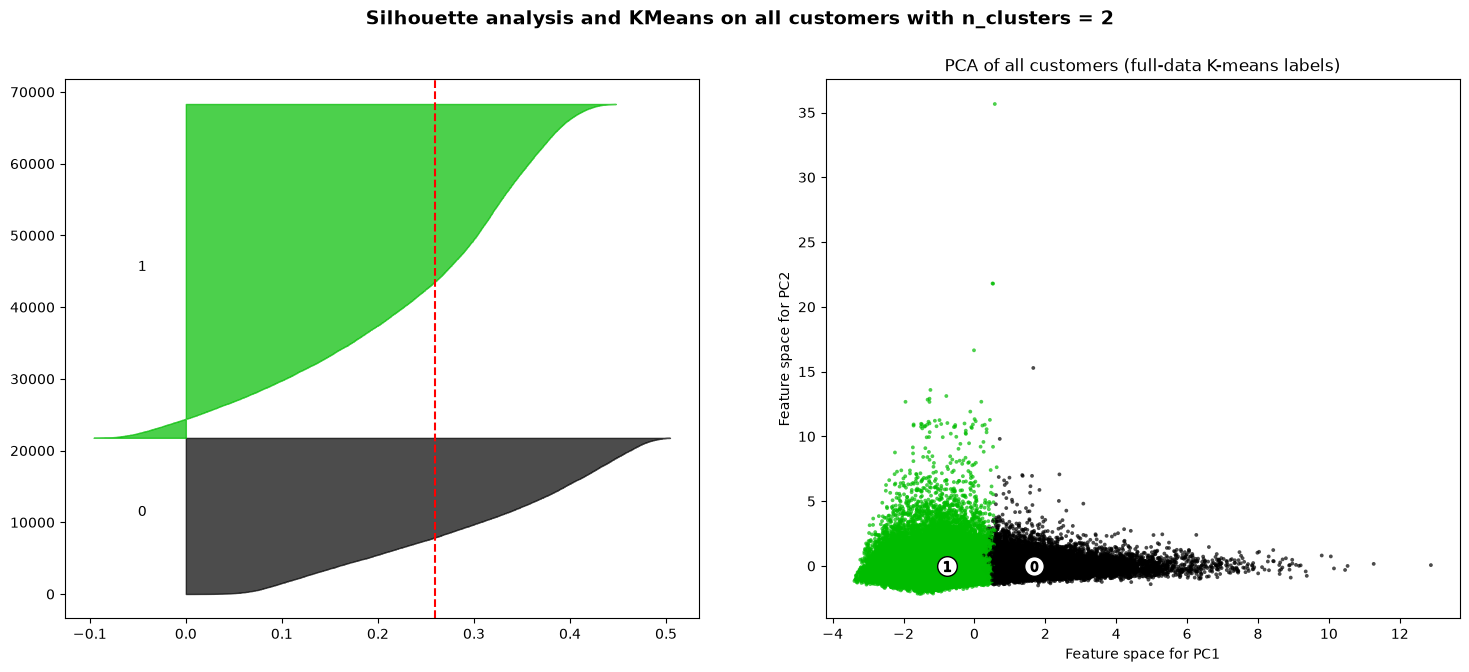

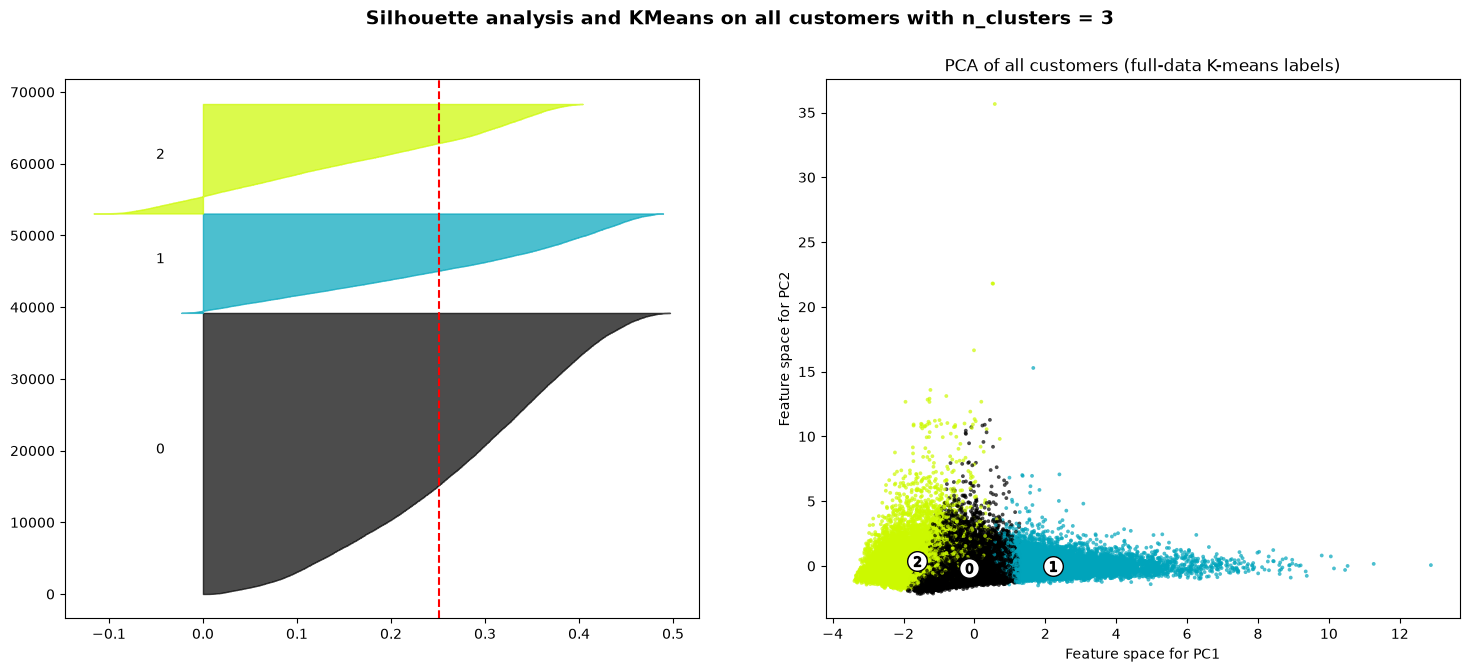

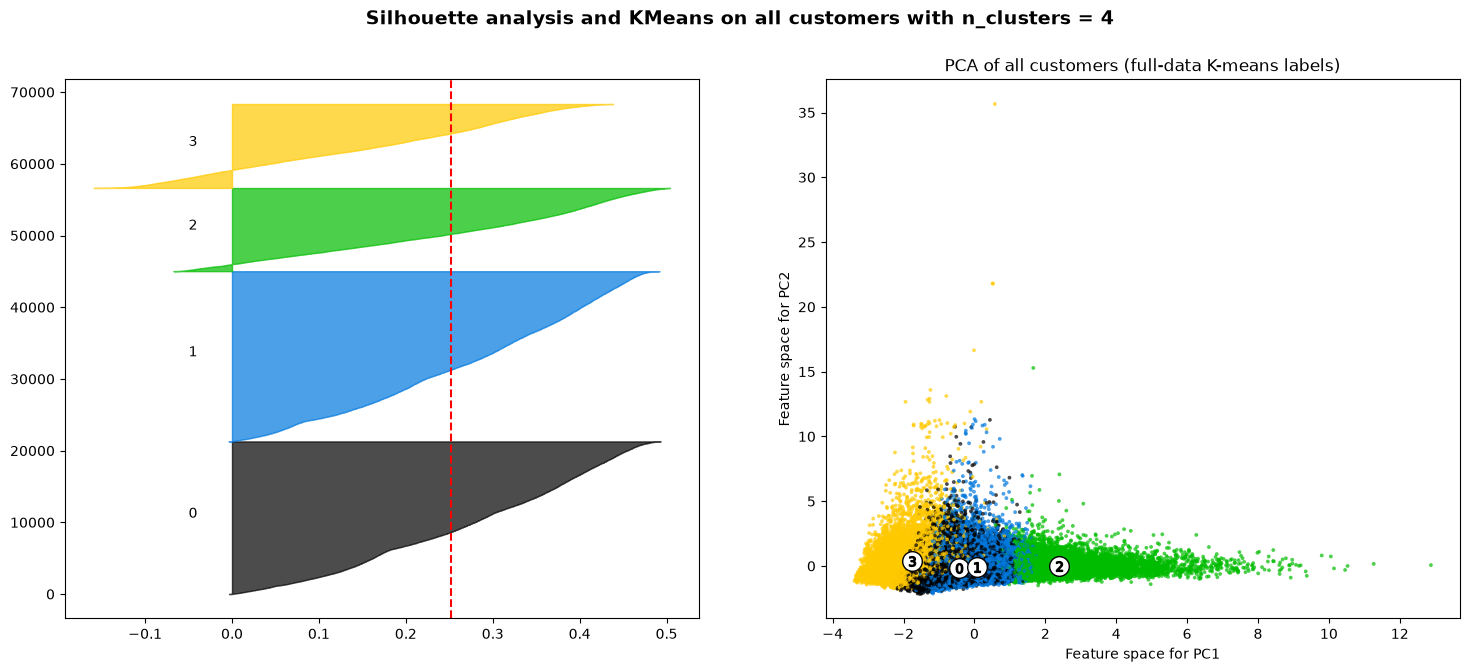

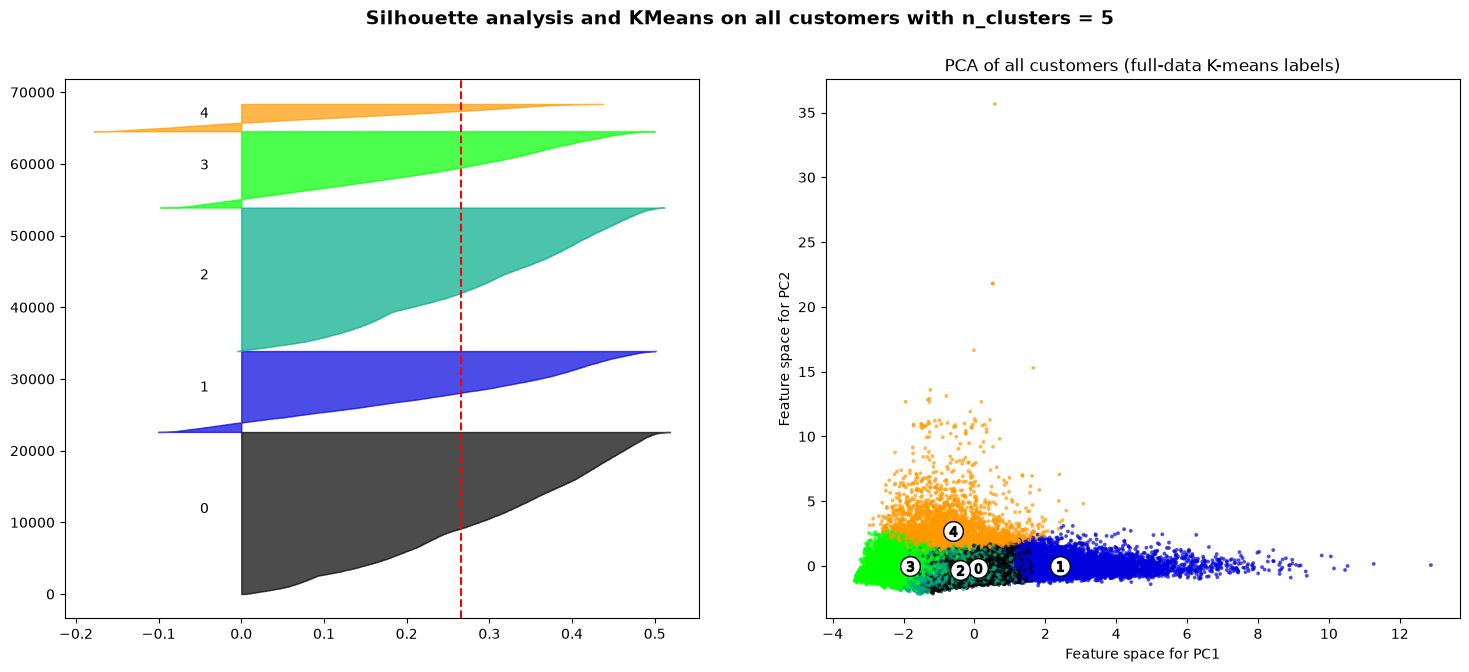

In [ ]:
if RECOMPUTE_DIAGNOSTICS:
    def plot_kmeans_silhouette_and_pca(
        X_scaled,
        labels,
        kmeans,
        n_clusters=None,
        silhouette_avg=None,
        silhouette_sample_data=None,
    ):
        """Function to plot silhouette analysis and PCA visualization
           for KMeans clustering.

        Parameters:
        - X_scaled: Scaled input data (DataFrame or ndarray).
        - labels: Cluster labels from KMeans.
        - kmeans: Fitted KMeans model.
        - n_clusters: Number of clusters.
        - silhouette_avg: Average silhouette score (dict - k, avg).
        - silhouette_sample_data: Silhouette scores for each sample
          (dict - k, scores).
        - random_state: Random state for reproducibility.
        - title_prefix: Prefix for the plot titles.
        """

        fig, (ax1, ax2) = plt.subplots(1, 2)
        fig.set_size_inches(18, 7)

        y_lower = 10

        sil_vals = silhouette_sample_data[n_clusters]  # shape (n_samples,)
        labels_vals = labels[n_clusters]

        for i in range(n_clusters):
            ith_cluster_silhouette_values = sil_vals[labels_vals == i]

            # Sort the silhouette values for cluster i
            ith_cluster_silhouette_values.sort()

            size_cluster_i = ith_cluster_silhouette_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_clusters)
            ax1.fill_betweenx(
                np.arange(y_lower, y_upper),
                0,
                ith_cluster_silhouette_values,
                facecolor=color,
                edgecolor=color,
                alpha=0.7,
            )

            # Label the silhouette plots with their cluster numbers at the middle.
            ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

            # Compute the new y_lower for next plot.
            y_lower = y_upper + 10  # 10 for the 0 samples.

        # The vertical line for average silhouette score of all the values.
        ax1.axvline(x=silhouette_avg[n_clusters], color="red", linestyle="--")

        pca = PCA(n_components=2, random_state=42)
        X_2d = pca.fit_transform(
            X_scaled
            if hasattr(X_scaled, "to_numpy")
            else np.asarray(X_scaled)
        )

        # 2nd Plot showing the actual clusters formed.
        colors = cm.nipy_spectral(labels[n_clusters].astype(float) / n_clusters)
        ax2.scatter(
            X_2d[:, 0],
            X_2d[:, 1],
            marker=".",
            s=30,
            lw=0,
            alpha=0.7,
            c=colors,
            edgecolor="k",
        )

        # Labeling the clusters.
        centers_2d = pca.transform(kmeans[n_clusters].cluster_centers_)  # (k, 2)
        # Draw white circles at cluster centers.
        ax2.scatter(
            centers_2d[:, 0],
            centers_2d[:, 1],
            marker="o",
            c="white",
            alpha=1,
            s=200,
            edgecolor="k",
        )

        for i, c in enumerate(centers_2d):
            ax2.scatter(
                c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k"
            )

        ax2.set_title("PCA of all customers (full-data K-means labels)")
        ax2.set_xlabel("Feature space for PC1")
        ax2.set_ylabel("Feature space for PC2")

        plt.suptitle(
            (
                "Silhouette analysis and KMeans on all customers "
                "with n_clusters = %d" % n_clusters
            ),
            fontsize=14,
            fontweight="bold",
        )


    # Now call the function for k=2 to 5
    for k in range(2, 6):
        plot_kmeans_silhouette_and_pca(
            X_scaled=X_scaled,
            labels=labels,
            kmeans=kmeans_models,
            n_clusters=k,
            silhouette_avg=silhouette_avg,
            silhouette_sample_data=silhouette_sample_data,
        )

        plt.show()

### Silhouette plot - Interpretation


*K = 2*

- Two very large clusters
- Broad silhouette distributions

*K = 3*

- One well-defined cluster
- Two adjacent clusters with some overlap
- Fewer negative silhouettes than k=4 or k=5

*K = 4 & 5*

- Higher silhouette value variability
- Presence of small, thin clusters
- Greater incidence of low and negative silhouette coefficients


*Summary*

The plots with 4 and 5 clusters show significant variability in cluster size and negative coefficients indicating weaker separation and greater overlap between clusters.

Plots with 2 and 3 clusters show less instances of negative coefficients in the saved coefficient plots, suggesting that either of these cluster values could be justified. Given the objective of customer segmentation where overly broad groupings are less desirable then the three-cluster solution is the preferred choice at this point.

The original hierarchical analysis is retained in the supplementary section as an exploratory view.



## Chosen value of k

The Elbow method and silhouette scores were used to identify a range of candidate values for k; however, these methods alone did not indicate a single, definitive choice.

The historical Ward dendrogram informed the original three-cluster interpretation. The saved full-data silhouette results shows that most customers have positive values for k=3, but k=5 has the highest average score. The original dendrograms are supplementary; the customer profiles below are regenerated using the corrected features.

On balance three clusters provide a practical trade-off between separation, and interpretability therefore the recommended choice:  **$k = 3$**









This is a choice balancing diagnostics and business interpretability, not a proven optimum.

In [13]:
# Refit only the chosen full-data k=3 model using the existing settings.
preprocessor = ColumnTransformer(transformers=[('num', StandardScaler(), selected_features)])
pipeline_k3 = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('clusterer', KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10))],
    memory=Memory(location='sk_cache', verbose=0), verbose=False,
)
pipeline_k3.fit(customer_data)
clusterer = pipeline_k3.named_steps['clusterer']
cluster_labels = clusterer.labels_
customer_data_scaled = pd.DataFrame(
    pipeline_k3.named_steps['preprocessor'].transform(customer_data),
    columns=selected_features, index=customer_data.index,
)
assert customer_data_scaled.index.equals(customer_data.index)
assert len(cluster_labels) == len(customer_data)
assert np.array_equal(cluster_labels, pipeline_k3.predict(customer_data))
print(f'Full-data k=3: {len(customer_data):,} customers, {len(selected_features)} features')
print(f'WCSS: {clusterer.inertia_:.8f}; full-data label alignment checks passed')


Full-data k=3: 68,300 customers, 5 features
WCSS: 205307.28644580; full-data label alignment checks passed



# Customer Segment Analysis



## Cluster number vs ID

To support further analysis we will assign the cluster labels to customer ID from the original dataset. The summary shows counts, percentages and median feature values for each segment.

In [14]:
customer_data_clustered = pd.DataFrame({'Cluster': cluster_labels}, index=customer_data.index)
segment_data = customer_data.join(customer_data_clustered)
segment_counts = segment_data.groupby('Cluster').size()
segment_summary = segment_data.groupby('Cluster')[selected_features].median()
segment_summary.insert(0, 'Customers', segment_counts)
segment_summary.insert(1, 'Percentage', segment_counts / len(customer_data) * 100)
assert segment_counts.sum() == len(customer_data)
assert np.isclose(segment_summary['Percentage'].sum(), 100)
print('Full-data segment summary: counts, percentages and median feature values')
display(segment_summary)
assert segment_data.index.equals(customer_data.index)
assert np.array_equal(segment_data['Cluster'].to_numpy(), cluster_labels)


Full-data segment summary: counts, percentages and median feature values


,Customers,Percentage,Frequency,Observed_Revenue,Avg_Unit_Cost,Age,Recency
Cluster,,,,,,,
0,39188,57.376281,9.0,1407.90,71.306548,43.0,163.0
1,13851,20.279649,22.0,4179.45,79.772222,38.0,75.0
2,15261,22.344070,3.0,553.80,69.550000,49.0,951.0


## Box plots

To provide insight into the cluster assignment to customer, and the corresponding customer characteristics we will create box plots for each cluster and selected feature combination.

We will plot both with and without outliers.

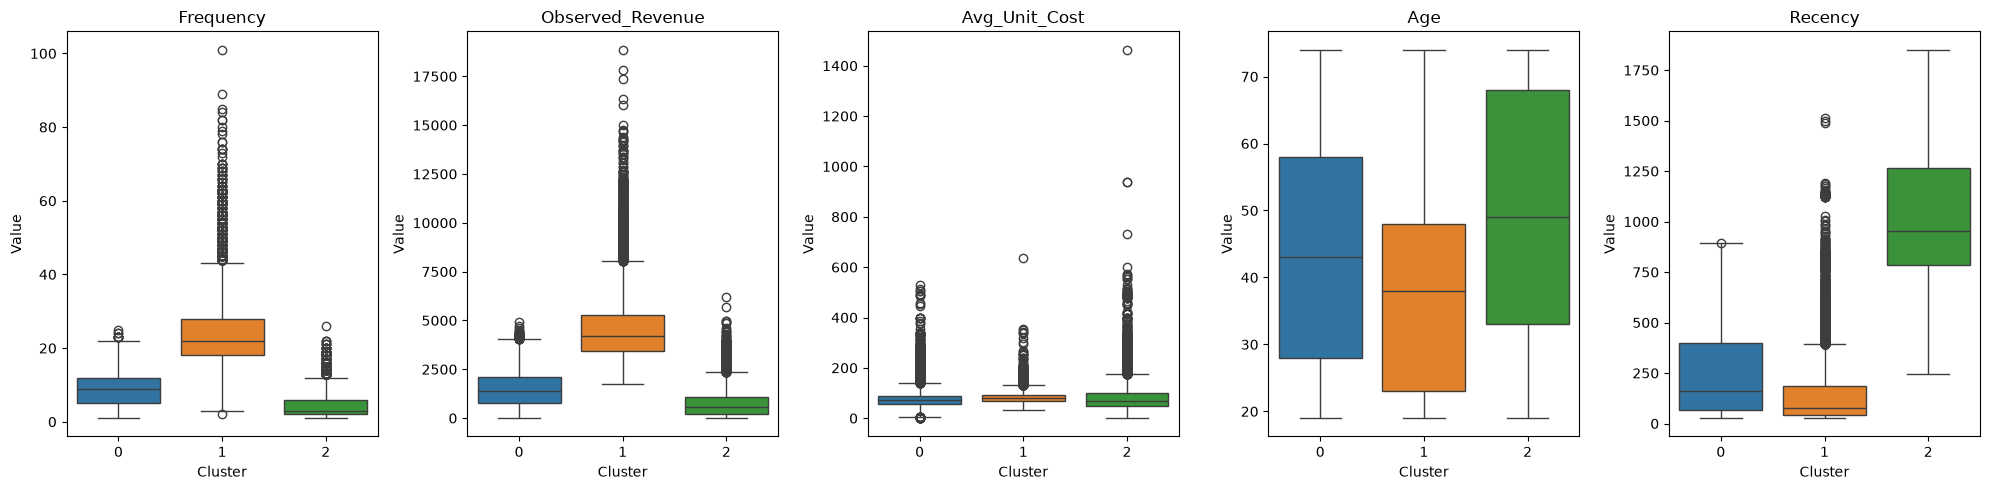

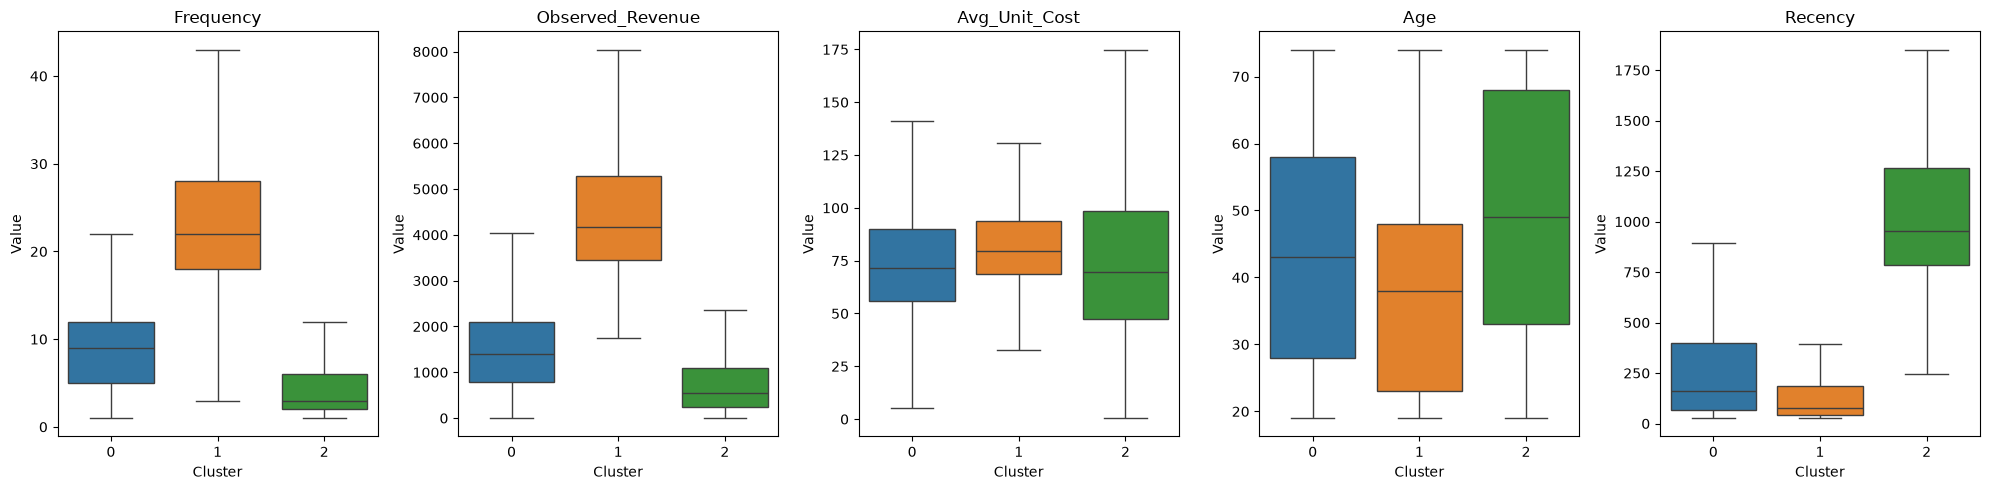

In [15]:
# identify feature columns (everything except cluster)

n_features = len(selected_features)

fig, axes = plt.subplots(
    nrows=1, ncols=n_features, figsize=(4 * n_features, 5), sharey=False
)

palette = {0: "#1f77b4"
           , 1: "#ff7f0e"
           , 2: "#2ca02c"
           , 3: "#662ca0"
           , 4: "#a02c32"}

# plot boxplots for each feature by cluster
for ax, feature in zip(axes, selected_features):
    sns.boxplot(
        data=customer_data,
        x=customer_data_clustered["Cluster"],
        hue=customer_data_clustered["Cluster"],
        y=feature,
        palette=palette,
        ax=ax,
        dodge=False,
    )
    ax.set_title(feature)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Value")
    if ax.legend_ is not None:
        ax.legend_.remove()


plt.tight_layout()
plt.show()


fig, axes = plt.subplots(
    nrows=1, ncols=n_features, figsize=(4 * n_features, 5), sharey=False
)


# plot boxplots for each feature by cluster (without outliers)
for ax, feature in zip(axes, selected_features):
    sns.boxplot(
        data=customer_data,
        x=customer_data_clustered["Cluster"],
        hue=customer_data_clustered["Cluster"],
        y=feature,
        palette=palette,
        ax=ax,
        dodge=False,
        showfliers=False,
    )
    ax.set_title(feature)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Value")
    if ax.legend_ is not None:
        ax.legend_.remove()


plt.tight_layout()
plt.show()

### Box Plot - Interpretation.

The following customer characteristics are evident from the refreshed segment summary and box plots. Numeric cluster labels are arbitrary.

**Cluster 2 (green) - WIN-BACK**

- Low frequency  
- Low Observed_Revenue  
- Very high Recency (haven’t bought in a long time)  
- Wide Age spread  
- Median age higher  
- High variance in Avg Unit Cost  
- Presence of high-value outliers  

Large outliers show some customers with high observed revenue or average unit costs; individual transactions need source review.  
**Lower activity / longer recency**; churn is a hypothesis requiring validation.

**Cluster 1 (orange) - RETAIN**

- Highest Frequency  
- Highest Observed_Revenue  
- Lowest Recency (they bought recently)  
- Moderate Avg Unit Cost  
- Slightly younger  

**Frequent / active customers**, high value, age indicates young adult to middle age. Potential core customer base; loyalty requires validation.

**Cluster 0 (blue) - CULTIVATE**

- Medium Frequency  
- Medium Observed_Revenue  
- Moderate Recency  
- Avg Unit Cost slightly lower  
- Age overlaps cluster 2  
- Slightly older (vs cluster 1)  
- Higher number of outliers in avg-cost than cluster 1  

**Active moderate-value customers**, age indicates adult to middle age, shows greater outliers in Avg Unit cost than cluster 1 – may reflect occasional large purchases. Presence of lower value outliers and larger spread in average unit cost might suggest more price-sensitive behaviour. This group may be more receptive to targeted promotions or discounts, though this would require validation against product-level data.

---

### Cluster Feature Interpretation Summary

| Feature | Cluster 2 (Lower Activity / Longer Recency) - Green | Cluster 1 (Higher Activity) - Orange | Cluster 0 (Active / Moderate Value) - Blue |
|--------|--------------------------------|---------------------------|--------------------------------------|
| **Frequency** | Low purchase frequency | Highest purchase frequency | Moderate purchase frequency |
| **Observed revenue during the dataset period** | Low overall Observed_Revenue with occasional extreme outliers | Highest Observed_Revenue, highest median | Medium Observed_Revenue |
| **Recency** | Very high recency (long time since last purchase) | Lowest recency (most recent purchasers) | Moderate recency |
| **Average Unit Cost** | High variability with extreme high-value outliers | Moderate and relatively stable | Slightly lower median with greater variability and occasional large outliers |
| **Age** | Wide age range; higher median age | Slightly younger customer base | Overlaps Cluster 2; slightly older than Cluster 1 |
| **Behaviour Insights** | Fewer purchases over the dataset period; potentially lapsed customers with occasional large purchases | Higher purchase frequency over the dataset period; high-revenue customers | Mixed purchasing behaviour; active but less consistent, with occasional large purchases |
| **Potential Commercial Focus** | Reactivation campaigns or churn prevention. Use targeted marketing campaigns and reminders to drive repeat purchases| Retention strategies, loyalty rewards, provide exclusive offers to keep engagement | Targeted promotions, cross-sell, value growth, offer incentives to encourage purchasing |




RETAIN, CULTIVATE and WIN-BACK are proposed campaign hypotheses, not validated responses. Avg_Unit_Cost is an unweighted mean of order-line unit costs, not a selling price; it does not establish price sensitivity. Loyalty, churn and campaign effectiveness require domain review and subsequent behaviour or controlled evaluation.

# Dimensionality Reduction and Visualisation

## Visualisation - PCA

2D visualisations of PCA-reduced data were included in the silhouette plots. We will repeat the visualisation now that we have chosen an chosen number of clusters and investigated the corresponding customer characteristics and attributes.

A 2D scatter plot using PCA-reduced data coloured by the cluster assignment matching the previous box-plots illustrates the hard cluster assignments. Overlap in a two-dimensional projection does not imply soft clustering or independently validate segment quality.



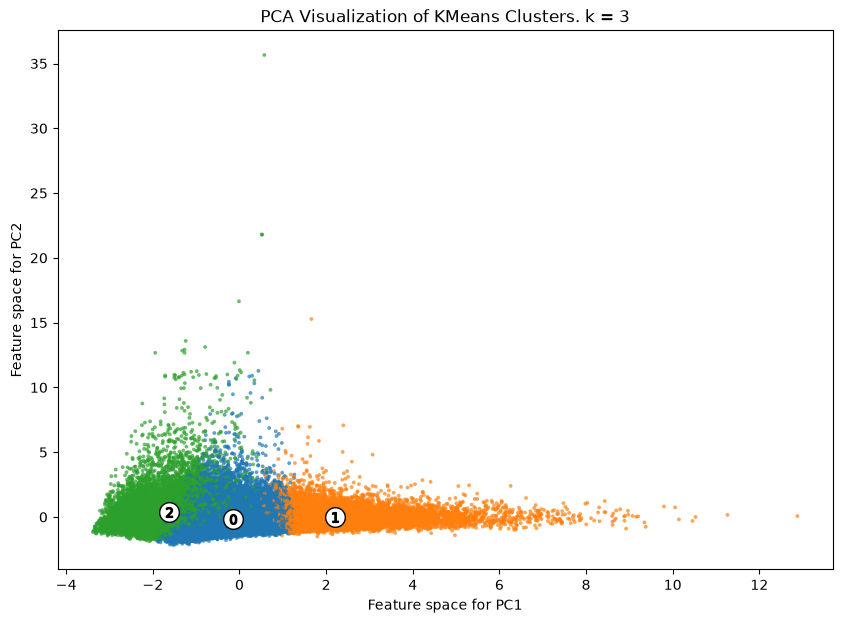

PCA explained variance ratio: [0.44334243 0.20751035]


In [16]:
# PCA transformation of scaled data for 2D visualization
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(customer_data_scaled.to_numpy())

# Plot the clustered data in 2D PCA space
plt.figure(figsize=(10, 7))

# colors for each cluster
colors = [palette[label] for label in cluster_labels]

# plot the data points
plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    marker=".",
    s=30,
    lw=0,
    alpha=0.7,
    c=colors,
    edgecolor="k",
)

# Labeling the clusters.
centers_2d = pca.transform(clusterer.cluster_centers_)  # (k, 2)
# Draw white circles at cluster centers.
plt.scatter(
    centers_2d[:, 0],
    centers_2d[:, 1],
    marker="o",
    c="white",
    alpha=1,
    s=200,
    edgecolor="k",
)
for i, c in enumerate(centers_2d):
    plt.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

plt.title("PCA Visualization of KMeans Clusters. k = 3")
plt.xlabel("Feature space for PC1")
plt.ylabel("Feature space for PC2")
plt.show()
print('PCA explained variance ratio:', pca.explained_variance_ratio_)


### PCA Interpretation

The PCA plot shows one distinct cluster and two overlapping clusters, with cluster 1 (orange) exhibiting the least projected overlap, while clusters 0 (blue) and 2 (green) show overlapping projected positions.

The overlap between clusters 0 and 2 is consistent with the box-plot analysis, together indicating possible similar customer characteristics and purchasing patterns, with separation driven by differences in recency.

Cluster 1 has the highest median Frequency and Observed_Revenue in the refreshed summary. PCA discards dimensions and does not independently validate segment quality.



# Approach and Findings

## Approach

The objective of this analysis was to perform customer segmentation with clustering models on an e-commerce dataset from a real-world organisation to aid improvements in marketing efforts.

This was undertaken in three main stages:

(1) Data exploration, preparation, feature engineering and EDA.

The dataset was reviewed for structure, completeness, and basic quality issues. Duplicate values were removed and data re-formatted and moved to appropriate datatypes to facilitate further data transformation and analysis (e.g. monetary values changed from text to numeric, date values stored in text changed into date datatype fields).

*Feature engineering*

- The dataset represented customer transactions (each row represented an order line), therefore appropriate aggregation of chosen segmentation features was performed to create a customer-level dataset with 5 new features.

*EDA*

- EDA was performed on the new features to gain insight into the data structure and distribution, and for use in selection of appropriate clustering methods. In particular the appearance of outliers in each feature was noted.

(2) K-means clustering

K-means clustering was performed, via a column transformer (StandardScaler implemented) and pipeline, and then several ML methods were employed (Elbow method with WCSS, Silhouette score, Hierarchical clustering) to provide further insight into the data, clustering structure in support of a decision for the reasonable number of clusters for the dataset and chosen customer features (or $k$ value).


(3) Customer segmentation

*Customer Characteristics*

Cluster values were assigned to the original aggregated feature labelled data, and statistical analysis performed to assign distinguishing customer characteristics for each identified segment. This was used to interpret the cluster grouping within a business context and provide information that would be of value to a more customer-centric approach to marketing initiatives.

*Dimensionality Reduction and Visualisation*

PCA and a 2D visualisation of the data were performed on the dataset to illustrate the cluster assignments and any observed overlap of customer characteristics. The original t-SNE plot is retained as supplementary material; it was not regenerated during the portfolio refresh.

Conclusions were then drawn on the strength of the cluster segregation, and customer designations inferred by the characteristics observed for each cluster.


## Findings

The dataset and chosen features were typically not normally distributed, and contained many outliers. Upon review no steps were performed to transform the data or remove outliers as the outlier values could represent customer behaviour, but their authenticity is unverified. Feature data should be of the same scale for k-means clustering, and therefore StandardScaler was used as the column transformer step in the pipeline. The subsequent output scaled dataset was used for all further ML models trained.

The Elbow method and silhouette scores provided a possible range of appropriate cluster values, but no definitive or obvious optimal value. Supplementing these with silhouette scores and a dendrogram using an appropriate linkage method for the dataset informed the original choice of three clusters; this is not a proven optimum.

A combination of all methods was required to inform the choice of $k$, and the value chosen was one of several that could have been justified (2,3, or 4) but on balance three appeared to offer the best trade-off between separation, and interpretability. The original Ward dendrogram offered an additional exploratory view of the selected value of $k$, with sensitivity to outliers remaining a limitation.

When the cluster values were applied to the original dataset, it was possible to infer three customer groups with differing purchasing profiles based on their characteristics.

- Cluster 0 - CULTIVATE – (ACTIVE / MODERATE VALUE)
- Cluster 1 - RETAIN - (Higher Activity; loyalty unverified)
- Cluster 2 - WIN-BACK - (Lower Activity / Longer Recency; churn unverified)

These would be subject to domain expertise validation, but customer-centric marketing could be undertaken targeted to the individual characteristics of the customer segments.

The results appear to show customer segmentation was achieved, although the segments were not completely separable and all had some overlap, illustrating projection overlap; K-means itself assigns hard cluster labels.

Further sub-segmentation could be beneficial after consultation with domain experts. i.e. define and validate a lower-activity population before treating it as a separate group and re-run the segmentation on active customers only. This would allow the clustering algorithm to focus on behavioural differences within the active customer base, potentially revealing more granular segments for growth and retention strategies.

For more granular clustering and sharply focused targeted marketing, additional customer or order attributes would be useful. For example, % ordered by product type or brand, whether orders were placed during promotional activities, and also geographical region as consumer behaviour and demand often vary significantly by region.

### Reference:
SAS, 2024. CUSTOMERS_CLEAN [Data set]. SAS. Last revised on 15 December 2021. [Accessed 20 February 2024].

# Supplementary original analysis

The following figures are saved outputs from the original analysis and were **not regenerated during the portfolio refresh**. They used all 68,300 customers and the original five scaled features: Frequency, CLV (now named Observed_Revenue), Avg_Unit_Cost, the original Age calculation and Recency. They provide historical context rather than validation of the corrected refreshed features.

## Original hierarchical clustering

Original settings: Euclidean distance; single, average, Ward, centroid and complete linkage; no sampling (`reduced_dataset_size=None`); dendrograms truncated to the last 10 merges.

Computing hierarchical clustering linkage matrix Z...


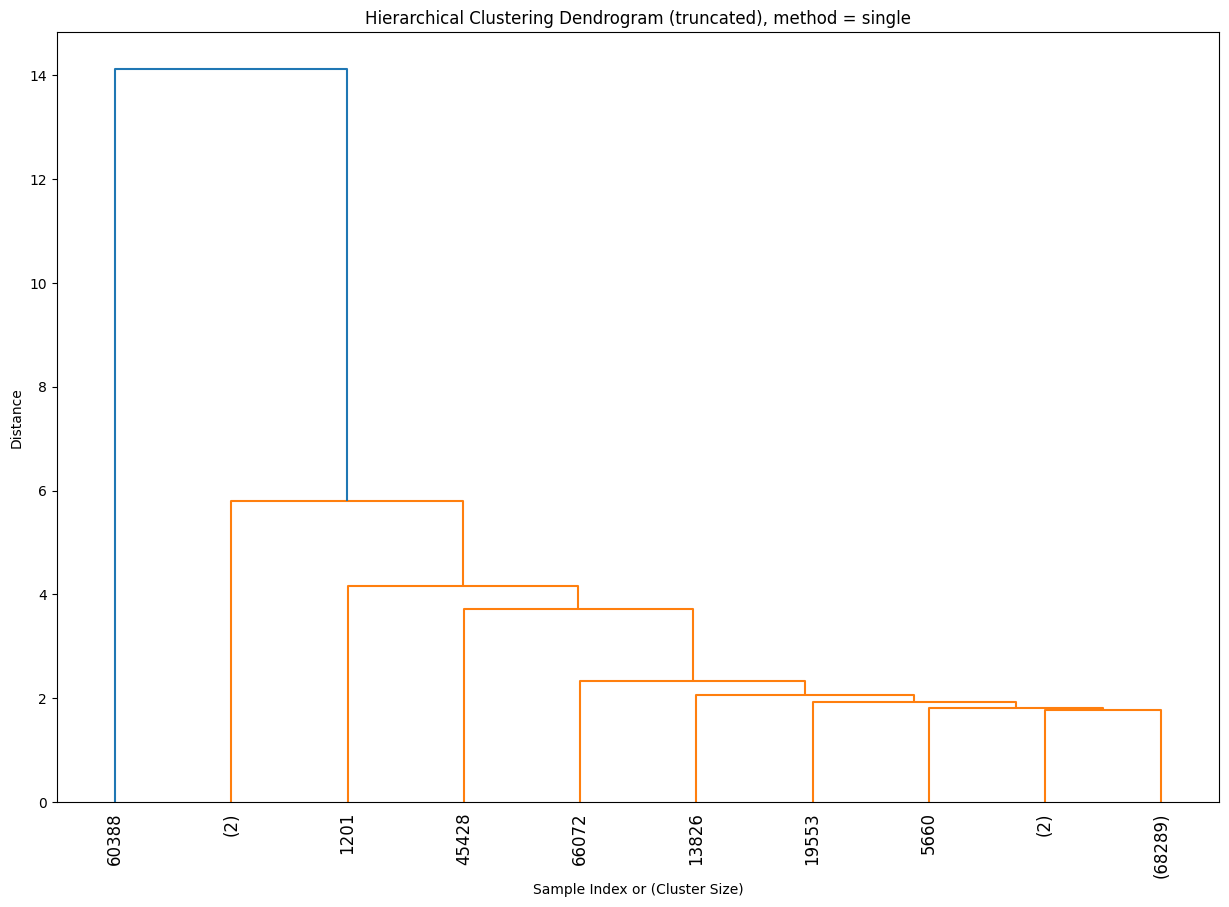

Computing hierarchical clustering linkage matrix Z...


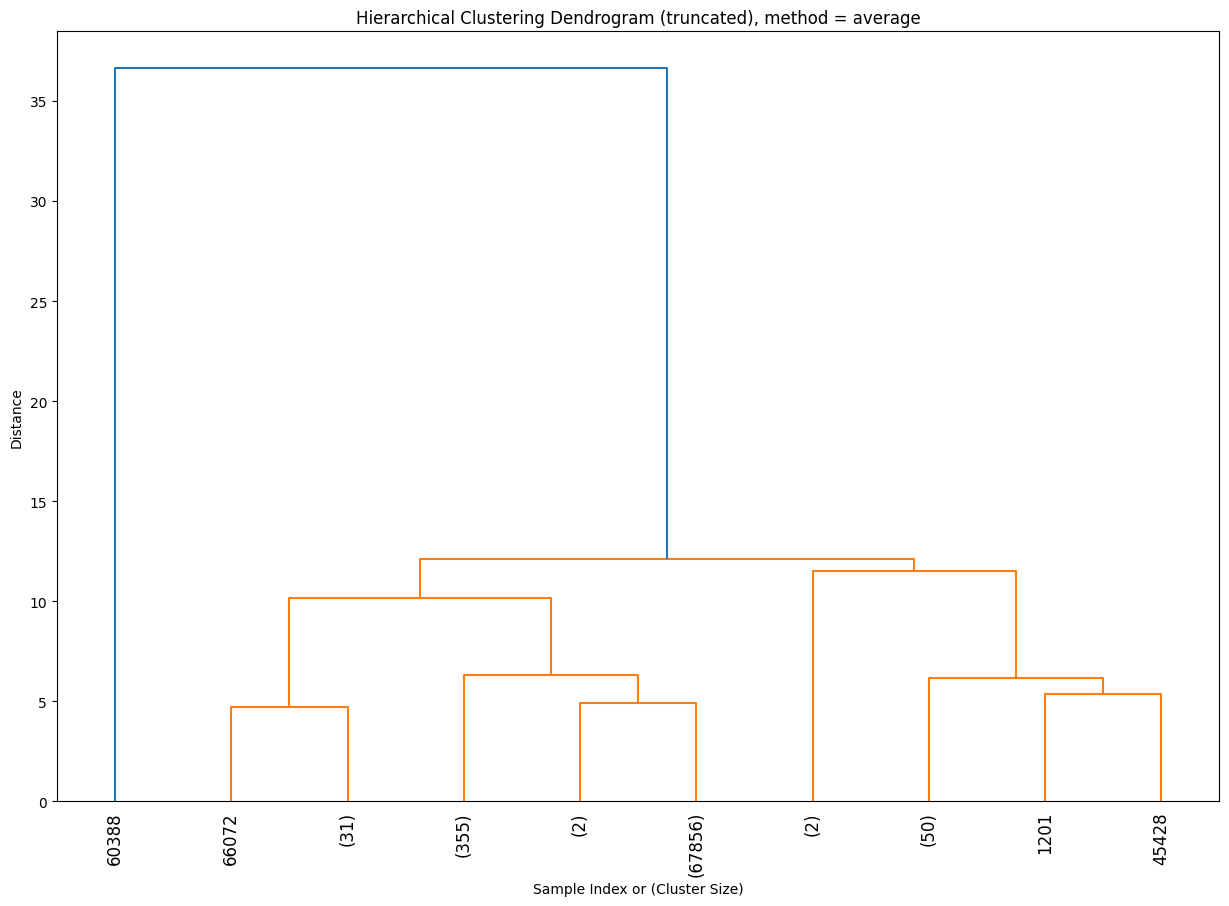

Computing hierarchical clustering linkage matrix Z...


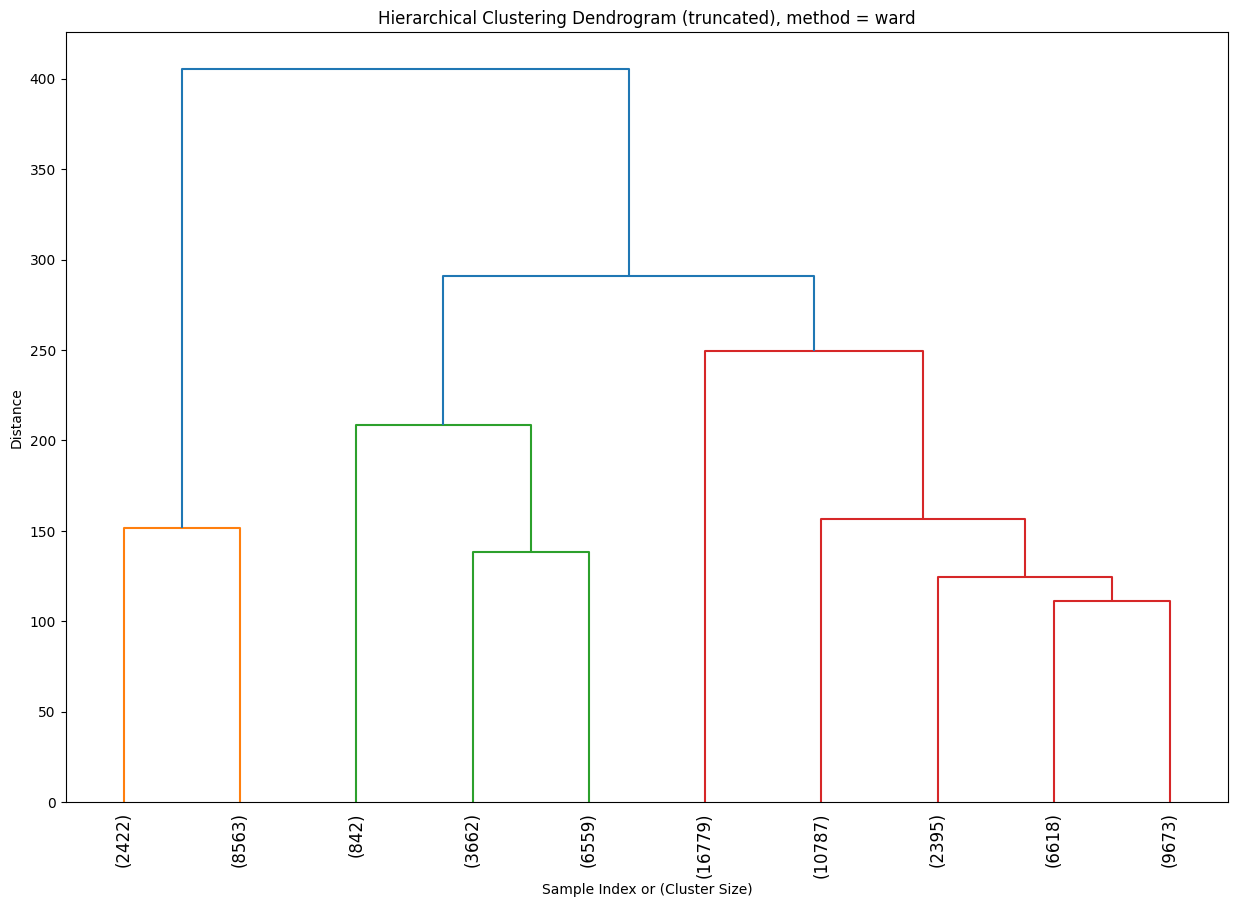

Computing hierarchical clustering linkage matrix Z...


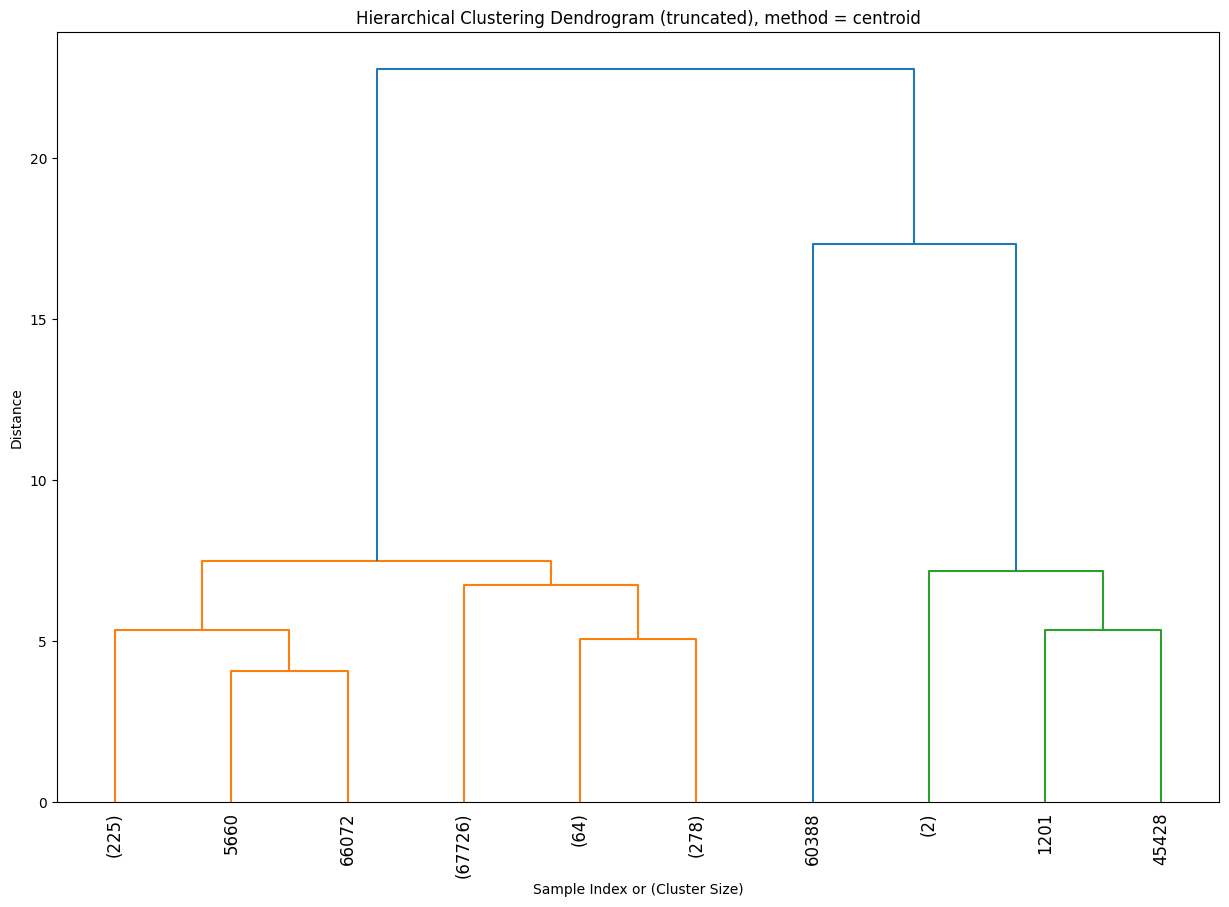

Computing hierarchical clustering linkage matrix Z...


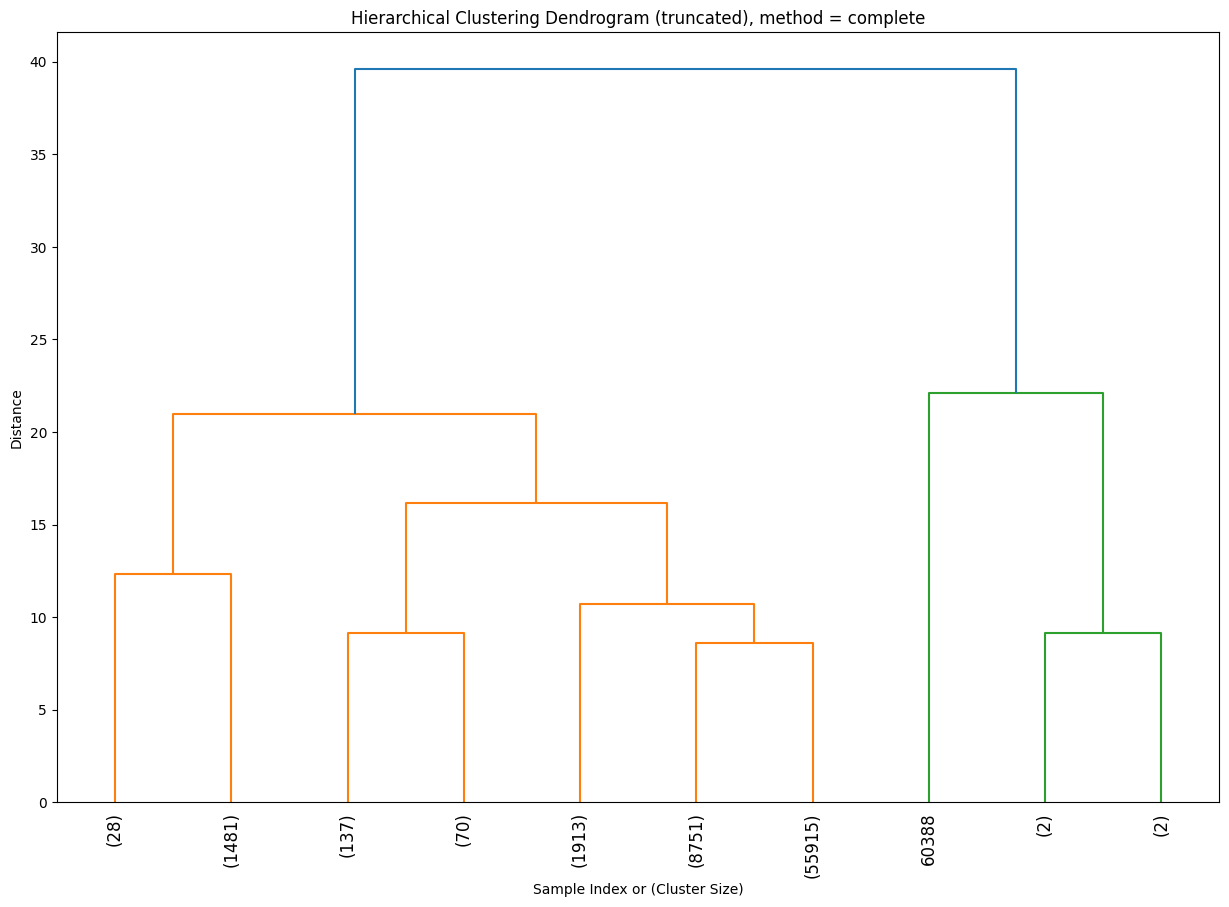

In [ ]:
# Saved original full-data dendrogram figures; this cell performs no calculation.


### Dendrogram Interpretation

The original saved figures show all methods evaluated on the full dataset. 

*Single linkage* is not suitable for this dataset - it is highly sensitive to outliers resulting in single-point or elongated clusters.

*Average, Centroid and Complete* all show unbalanced cluster sizes and in some cases isolated small clusters. These dendrograms do not offer clear or consistent evidence in to support a specific choice for the number of clusters. Although currently out-of-scope, should a future review of feature outlier points by a domain expert deem it valid to run analysis with outliers removed, these methods should be revisited as there would be an increase in their suitability.


*Ward’s method* focuses on minimising increases in within-cluster squared variation. It remains sensitive to outliers. The historical Ward dendrogram is easier to interpret, but this does not verify the extreme records or independently establish an optimum.

The Ward dendrogram shows a clear separation between the data when moving from one cluster to two clusters, suggesting that k=2 represents the strongest split. However, below this the data separates further into three well-formed groups with a relatively large distance gap between two and three.

The distance gap between three and four clusters is relatively small, suggesting that additional splits beyond three provide diminishing returns. A cut point at 290 just below the largest distance jump on the tree (290 to 405) supports a three-cluster solution.


In combination with the silhouette plots, the historical dendrograms informed a choice of $k = 3$. These figures were not regenerated with the corrected features.



## Optional hierarchical calculation

Set `RUN_HIERARCHICAL=True` explicitly to calculate these five methods on the current corrected full-data features. This cell is skipped by default and has no regenerated saved output.

In [ ]:
if RUN_HIERARCHICAL:
    for method in ['single', 'average', 'ward', 'centroid', 'complete']:
        Z = linkage(customer_data_scaled.to_numpy(), method=method, metric='euclidean')
        plt.figure(figsize=(15, 10))
        dendrogram(Z, truncate_mode='lastp', p=10, leaf_rotation=90, leaf_font_size=12)
        plt.title(f'Hierarchical Clustering Dendrogram (truncated), method = {method}')
        plt.xlabel('Sample Index or (Cluster Size)')
        plt.ylabel('Distance')
        plt.show()
        del Z


## Original t-SNE visualisation

Original settings: full scaled feature data, `TSNE(n_components=2, perplexity=20.0)`, **no fixed random_state**, and no prior PCA. The original code was:

```python
TSNE_model = TSNE(n_components=2, perplexity=20.0)
TSNE_transformed_data = TSNE_model.fit_transform(customer_data_scaled)
```

The figure below belongs to those original inputs and unseeded settings, not to the optional seeded code shown later.

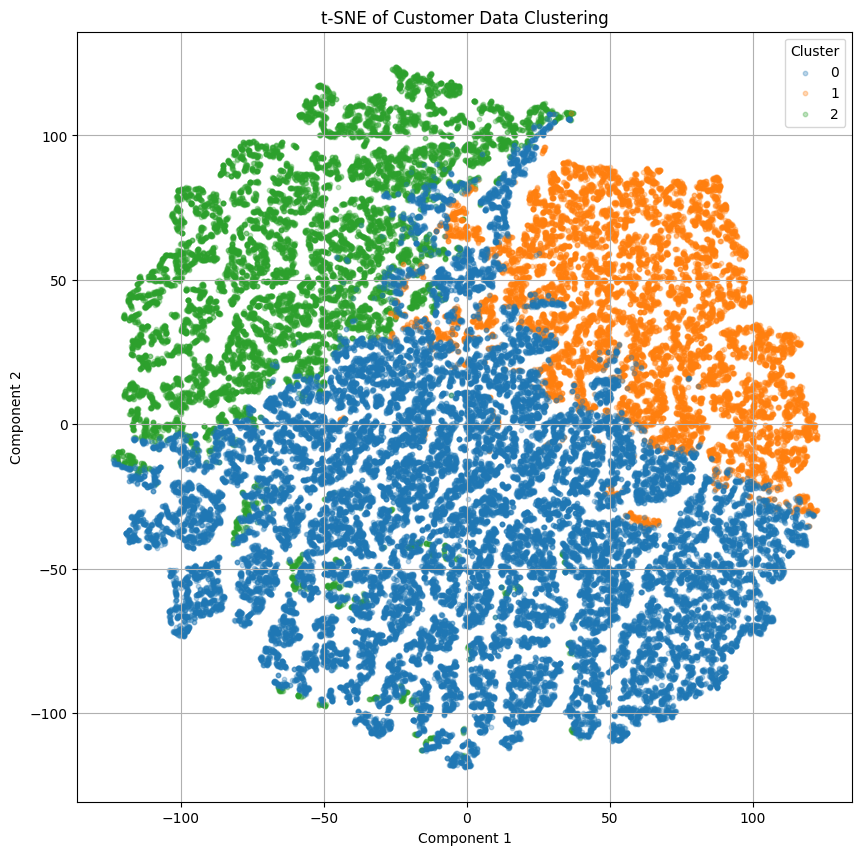

In [ ]:
# Saved original unseeded t-SNE figure; this cell performs no calculation.

### t-SNE Interpretation

Given the small number of input features, t-SNE was applied directly to the scaled feature space without prior PCA reduction. The saved original code uses perplexity 20 without a fixed seed. This original figure was not regenerated during the portfolio refresh.

The t-SNE projection shows separation of cluster 1, which forms a compact and well-defined region with minimal overlap.

Clusters 0 and 2 display substantial overlap in the embedding, illustrating the historical interpretation that these segments have customer characteristics that overlap and may be separated primarily in engagement intensity (recency)


## Dimensionality Reduction Review

Both PCA and t-SNE provided complementary insights into the structure of the data. PCA offered a linear view of the data, allowing assessment of overall variance and broad separation between clusters. The PCA projection showed one clearly differentiated cluster, while the remaining two clusters had substantial overlap.

The historical t-SNE embedding illustrated the more clearly differentiated cluster (1), which formed a compact and well-defined region. In contrast, the other two clusters showed more significant overlap, suggesting they may represent adjacent customer segments rather than sharply separable groups.

Overlap was visible between all clusters, with cluster 1 showing minimal overlap relative to 0 and 2. K-means assigns one hard label to each customer. Projection overlap does not imply soft clustering or independently establish continuous population structure.

Overall, the dimension reduction results are effective in demonstrating that the customer segmentation consists of one clearly distinct segment and two overlapping projected groups. As both techniques involve dimensionality reduction and information loss, neither PCA nor t-SNE are appropriate to determine or to justify the number of clusters.

In summary, PCA and t-SNE are a useful tool to visualise segmentation and clustering in customer segmentation, however loss of interpretability inherent in these methods requires that we use them in conjunction with labelled data analysis to helps businesses find meaningful customer segments.


## Optional seeded t-SNE

Set `RUN_TSNE=True` explicitly to use all current corrected customers with perplexity 20 and random_state 42. This retains the added reproducibility seed. The cell is skipped by default and has no regenerated saved figure.

In [ ]:
if RUN_TSNE:
    # t-SNE transformation
    TSNE_model = TSNE(n_components=2, perplexity=20.0, random_state=RANDOM_STATE)
    # transform the scaled data
    TSNE_transformed_data = TSNE_model.fit_transform(customer_data_scaled)

    # Visualise the output.
    # one scatter plot per cluster
    def plot_embedding(X, title, y):
        y = np.asarray(y).astype(int)  # ensure numeric
        plt.figure(figsize=(10, 10))
        for c in np.unique(y):
            plt.scatter(
                X[y == c, 0],
                X[y == c, 1],
                label=str(c),
                s=10,
                alpha=0.3,
                zorder=-c,
            )
        plt.xlabel("Component 1")
        plt.ylabel("Component 2")
        plt.legend(title="Cluster")
        plt.title(title)
        plt.grid(True)
        plt.show()


    plot_embedding(
        TSNE_transformed_data, "t-SNE of Customer Data Clustering", cluster_labels
    )